# This is a Jupyter Notebook for Convolutional PTRA

In [1]:
import pandas as pd
import numpy as np
import glob
import os
import ast
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.interpolate import interp1d

# Read the input file

In [2]:
# Input File name
vulnerability_file = "vulnerabilityModel.csv"

# Read CSV file
df_vulnerability = pd.read_csv(vulnerability_file)

IM = df_vulnerability["flow depth [m]"].values
IM = IM[1:]   # if the first value is very small 1e-6

# Show first rows
df_vulnerability.head()


,flow depth [m],16th percentile vulnerability,median vulnerability,84th percentile vulnerability,logarithmic standard deviation,epistemic uncertainty in the median
0,0.000001,0.001355,0.003680,0.009995,0.999276,0.031743
1,0.010000,0.001344,0.003705,0.010215,1.014033,0.058468
2,0.020000,0.001340,0.003736,0.010411,1.024948,0.077940
3,0.030000,0.001327,0.003760,0.010650,1.041168,0.099379
4,0.040000,0.001327,0.003800,0.010885,1.052292,0.117919


# Read the Tsumani Hazard Simulations

In [3]:
# Read hazard curves main file
df_per_hazard_curve = pd.read_csv("perc_hazard_curves_marzamemi.txt",sep=r"\s+")

print(df_per_hazard_curve.head())

IM_hazard = df_per_hazard_curve["thresholds"].values

print(IM_hazard)

# Read hazard curves file
hazard_curves = np.loadtxt(
    "1000_hazard_curves_marzamemi.txt"
)

print(hazard_curves.shape)


print(hazard_curves)

   thresholds      mean        p2       p16       p84       p98
0        0.01  0.031531  0.005645  0.010643  0.054049  0.082409
1        0.05  0.031155  0.005620  0.010425  0.053835  0.081442
2        0.10  0.026326  0.004857  0.008516  0.046466  0.067604
3        0.20  0.011544  0.001107  0.003289  0.021411  0.031439
4        0.30  0.005337  0.000210  0.001125  0.009793  0.016014
[0.01 0.05 0.1  0.2  0.3  0.5  0.8  1.   1.5  2.   2.5  3.   3.6  4.32
 5.18]
(15, 1000)
[[6.94143699e-02 4.85058550e-02 1.87504264e-02 ... 1.56165552e-02
  1.62547388e-02 3.08623087e-02]
 [6.87742586e-02 4.81653433e-02 1.85887621e-02 ... 1.55614594e-02
  1.57544291e-02 3.05112268e-02]
 [5.73415660e-02 4.01773031e-02 1.63506782e-02 ... 1.45515580e-02
  1.10542304e-02 2.68454974e-02]
 ...
 [1.82842862e-06 1.69319636e-06 1.46992668e-06 ... 5.14435151e-06
  1.27909604e-06 5.35881815e-06]
 [8.67500710e-07 8.61135137e-07 3.90208847e-07 ... 3.24159771e-06
  7.64040765e-07 1.80036616e-06]
 [0.00000000e+00 3.80572955

# Plot Hazard Curves

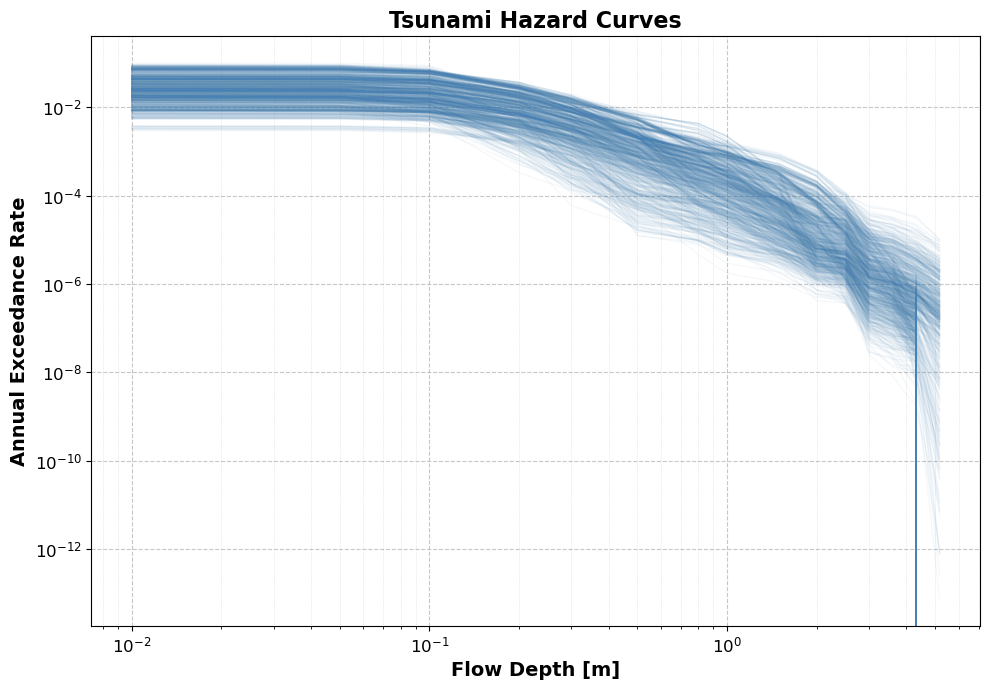

In [4]:
# Create figure
fig, ax = plt.subplots(figsize=(10,7))


# Plot all hazard curves
for i in range(hazard_curves.shape[1]):

    ax.loglog(
        IM_hazard,
        hazard_curves[:,i],
        color='steelblue',
        linewidth=1,
        alpha=0.05
    )


# Labels
ax.set_xlabel(
    "Flow Depth [m]",
    fontsize=14,
    fontweight='bold'
)

ax.set_ylabel(
    "Annual Exceedance Rate",
    fontsize=14,
    fontweight='bold'
)


# Title
ax.set_title(
    "Tsunami Hazard Curves",
    fontsize=16,
    fontweight='bold'
)


# Grid
ax.grid(True,
        which='major',
        linestyle='--',
        linewidth=0.8,
        alpha=0.7)

ax.grid(True,
        which='minor',
        linestyle=':',
        linewidth=0.5,
        alpha=0.5)


# Tick style
ax.tick_params(axis='both',
               which='major',
               labelsize=12)


# Tight layout
plt.tight_layout()

plt.show()

# Main Loop for convolving vulnerability and loss λ(LR > lr)=∫ P(LR > lr | IM)·|dλ(IM)|

In [5]:
# STEP A — Define LR Thresholds
lr = np.arange(0.01, 1.01, 0.01)


# STEP B — Read Vulnerability Statistics
medianLoss_IM = (df_vulnerability["median vulnerability"].values)
medianLoss_IM = medianLoss_IM[1:]

ElogLoss_IM = np.log(np.maximum(medianLoss_IM,1e-30))

siglogLoss_IM = (df_vulnerability["logarithmic standard deviation"].values)
siglogLoss_IM = siglogLoss_IM[1:]

# STEP C — Construct CCDF (G) Matrix (nIM , nLR): rows	IM levels and columns LR thresholds 
G_LR_IM = (1-norm.cdf(np.log(lr)[np.newaxis,:],ElogLoss_IM[:,np.newaxis],siglogLoss_IM[:,np.newaxis]))

print(f"The dimension of the Constructed CCDF (G) Matrix is {G_LR_IM.shape}")


# STEP D — Loop over hazard curves
dIM = IM[1]-IM[0]
LEC_all = []
for i in range(hazard_curves.shape[1]):

    lambda_hazard = hazard_curves[:,i]

    # Construct log-hazard interpolator
    #loglambda = np.interp(IM,IM_hazard,np.log(np.maximum(lambda_hazard,1e-30)))
    interpHazard = interp1d(IM_hazard,np.log(np.maximum(lambda_hazard,1e-30)),kind='linear',fill_value='extrapolate')
    
    lambda_IMp = np.exp(interpHazard(IM + dIM/2))
    lambda_IMm = np.exp(interpHazard(IM - dIM/2))
    dlambda_IM = np.maximum(lambda_IMm - lambda_IMp,0)

    # STEP E — Perform Convolution
    risk_contribution = (G_LR_IM * dlambda_IM[:,np.newaxis])

    LEC = np.sum(risk_contribution , axis=0)

    LEC_all.append(LEC)


LEC_all = np.array(LEC_all)

print (f"LEC_all has the shape of {LEC_all.shape}")


The dimension of the Constructed CCDF (G) Matrix is (500, 100)
LEC_all has the shape of (1000, 100)


# Plot Loss Exceedance Curve for all simulations¶

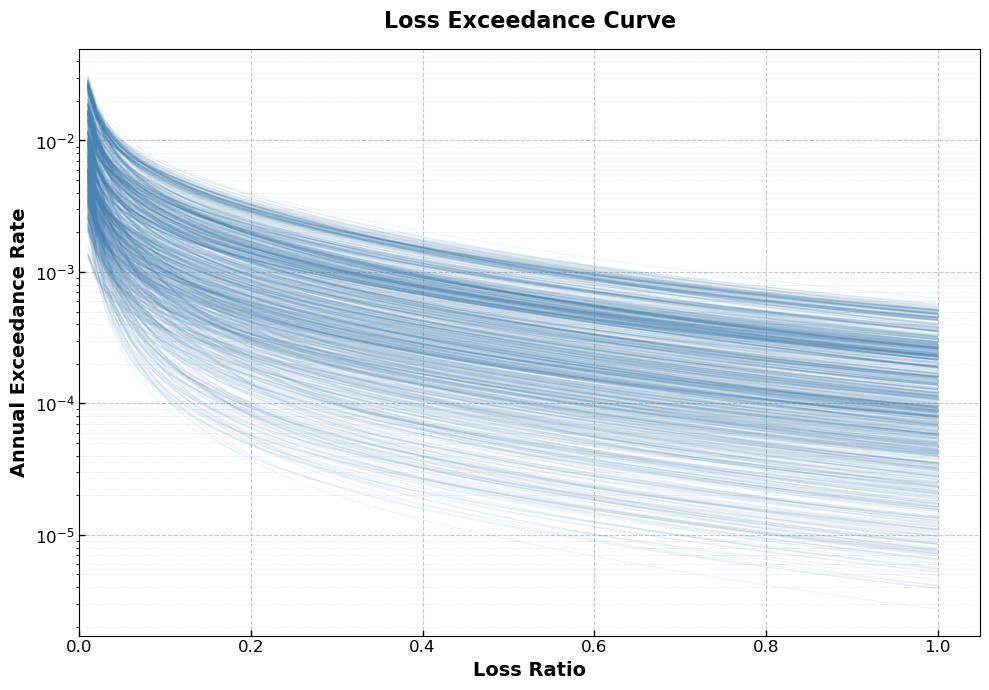

In [6]:
# -----------------------------------
# Create Figure
# -----------------------------------

fig, ax = plt.subplots(figsize=(10,7))

for i in range(LEC_all.shape[0]):
    
    ax.semilogy(lr,LEC_all[i,:],linewidth=1,color='steelblue',alpha=0.08)


ax.set_xlabel("Loss Ratio",
              fontsize=14,
              fontweight='bold')

ax.set_ylabel("Annual Exceedance Rate",
              fontsize=14,
              fontweight='bold')

ax.set_title("Loss Exceedance Curve",
             fontsize=16,
             fontweight='bold',
             pad=15)

ax.grid(True,
        which='major',
        linestyle='--',
        linewidth=0.8,
        alpha=0.7)

ax.grid(True,
        which='minor',
        linestyle=':',
        linewidth=0.5,
        alpha=0.5)

ax.tick_params(axis='both',
               which='major',
               labelsize=12,
               direction='in',
               length=4,
               width=1.0)

plt.tight_layout()

ax.set_xlim(left=0)

plt.show()


# Calculate the mean LEC and the 16th and 84th percentiles

In [7]:
def reliability(data):
    """
    Calculate the mean and standard deviation (sigma) of samples.
    """
    firstM = np.mean(data, axis=1)
    secondM = np.mean(data**2, axis=1)
    sigma = np.sqrt(secondM - firstM**2)
    
    return firstM, sigma

In [8]:
logLEC_all = np.log(np.maximum(LEC_all, 1e-30))

logLEC_all_T = logLEC_all.T

meanLogLEC, sigmaLogLEC = reliability(logLEC_all_T)

medianLEC = np.exp(meanLogLEC)
meanLEC = medianLEC*np.exp(0.5*sigmaLogLEC**2)

LEC_16 = np.exp(meanLogLEC - sigmaLogLEC)
LEC_84 = np.exp(meanLogLEC + sigmaLogLEC)


# Plot Loss Exceedance Curve for all simulations¶

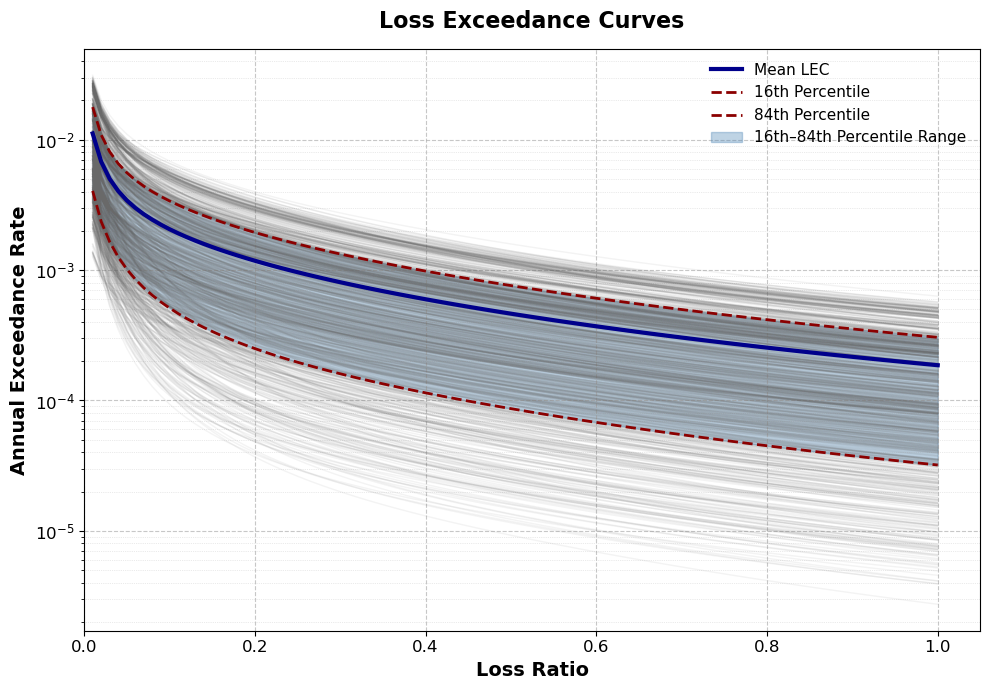

In [10]:

fig, ax = plt.subplots(figsize=(10,7))


for i in range(LEC_all.shape[0]):
    
    ax.semilogy(lr,
                LEC_all[i,:],
                color='dimgrey',
                linewidth=1,
                alpha=0.08)


ax.semilogy(lr,
            meanLEC,
            color='darkblue',
            linewidth=3,
            label='Mean LEC')


ax.semilogy(lr,
            LEC_16,
            color='darkred',
            linewidth=2,
            linestyle='--',
            label='16th Percentile')


ax.semilogy(lr,
            LEC_84,
            color='darkred',
            linewidth=2,
            linestyle='--',
            label='84th Percentile')


ax.fill_between(lr,
                LEC_16,
                LEC_84,
                color='steelblue',
                alpha=0.35,
                label='16th–84th Percentile Range')


ax.set_xlabel("Loss Ratio",
              fontsize=14,
              fontweight='bold')


ax.set_ylabel("Annual Exceedance Rate",
              fontsize=14,
              fontweight='bold')


ax.set_title("Loss Exceedance Curves",
             fontsize=16,
             fontweight='bold',
             pad=15)


ax.set_xlim(left=0)


ax.grid(True,
        which='major',
        linestyle='--',
        linewidth=0.8,
        alpha=0.7)


ax.grid(True,
        which='minor',
        linestyle=':',
        linewidth=0.5,
        alpha=0.5)


ax.tick_params(axis='both',
               which='major',
               labelsize=12)


ax.legend(fontsize=11,
          frameon=False)


plt.tight_layout()

plt.savefig(
    "convolutionPTRA.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()